In [1]:
# E1: environment and code
import sys
import subprocess
from pathlib import Path

REPO_USER = "agontuk19"
REPO_NAME = "mars-rover-segmentation"
IS_KAGGLE = Path("/kaggle").exists()

if IS_KAGGLE:
    ROOT = Path(f"/kaggle/working/{REPO_NAME}")
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        url = f"https://{token}@github.com/{REPO_USER}/{REPO_NAME}.git"
    except Exception:
        token = None
        url = f"https://github.com/{REPO_USER}/{REPO_NAME}.git"

    cmd = ["git", "-C", str(ROOT), "pull"] if ROOT.exists() else ["git", "clone", url, str(ROOT)]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        msg = result.stderr.replace(token, "***") if token else result.stderr
        raise RuntimeError(f"git failed. Is Internet On? Repo name/token correct?\n{msg}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src").exists(), f"src/ not found under {ROOT}"
sys.path.append(str(ROOT))
print("Environment:", "Kaggle" if IS_KAGGLE else "local", "| ROOT:", ROOT)

Environment: Kaggle | ROOT: /kaggle/working/mars-rover-segmentation


In [2]:
# E2: configuration, device, test data
from src.utils.common import seed_everything, get_device
from src.data.preprocessing import IGNORE_INDEX, CLASS_NAMES
from src.data.dataset import load_raw_datasets, build_test_loaders

SEED = 42
IMG_SIZE = 512                          # must match the training resolution
BATCH_SIZE = 8 if IS_KAGGLE else 2
NUM_WORKERS = 2 if IS_KAGGLE else 0     # 0 is safest on macOS

OUT_DIR = Path("/kaggle/working/outputs/evaluation") if IS_KAGGLE else ROOT / "results" / "baseline"
OUT_DIR.mkdir(parents=True, exist_ok=True)

seed_everything(SEED)
device = get_device()
use_amp = device.type == "cuda"

raw_datasets = load_raw_datasets()
test_loaders = build_test_loaders(raw_datasets, IMG_SIZE, BATCH_SIZE, NUM_WORKERS,
                                  pin_memory=device.type == "cuda")

print("Device:", device, "| AMP:", use_amp)
print({split: len(loader.dataset) for split, loader in test_loaders.items()})

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  471MB            

... (28 outputs left out)

Generating test_min1 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min2 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min3 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Device: cuda | AMP: True
{'test_min1': 322, 'test_min2': 322, 'test_min3': 322}


In [3]:
# E3: find best.pt and load the model
from src.evaluation.evaluate import load_best_model

CKPT_OVERRIDE = None   # or Path("/path/to/best.pt") to force a specific file

def find_checkpoint():
    if CKPT_OVERRIDE is not None:
        return Path(CKPT_OVERRIDE)
    roots = ([Path("/kaggle/input"), Path("/kaggle/working")] if IS_KAGGLE
             else [ROOT / "outputs", ROOT / "results", ROOT / "checkpoints"])
    for root in roots:
        if root.exists():
            hits = sorted(root.rglob("best.pt"))
            if hits:
                return hits[0]
    raise FileNotFoundError("best.pt not found. On Kaggle attach the training notebook's output as an input; "
                            "locally put best.pt under outputs/ or results/.")

CKPT_PATH = find_checkpoint()
print("Using:", CKPT_PATH)
model = load_best_model(CKPT_PATH, device)

Using: /kaggle/input/notebooks/agontuk19/mars-rover-segmentation/outputs/baseline/best.pt
Loaded epoch 15 (val mIoU at save time: 0.7415)


In [4]:
# E4: metrics on test_min1 / test_min2 / test_min3
from src.evaluation.evaluate import evaluate_splits

results, confusions = evaluate_splits(model, test_loaders, device, use_amp=use_amp, return_confusion=True)
print(results.round(4).to_string(index=False))

results.to_csv(OUT_DIR / "test_results.csv", index=False)
results.to_json(OUT_DIR / "test_results.json", orient="records", indent=2)

test_min1:   0%|          | 0/41 [00:00<?, ?it/s]

test_min2:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d0be0361bc0>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d0be0361bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d0be0361bc0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", l

test_min3:   0%|          | 0/41 [00:00<?, ?it/s]

    split   loss   miou  pixel_acc  iou_Soil  iou_Bedrock  iou_Sand  iou_Big Rock
test_min1 0.2753 0.6578     0.9175    0.9056       0.7976    0.8265        0.1017
test_min2 0.1327 0.7118     0.9553    0.9504       0.8734    0.9032        0.1199
test_min3 0.0710 0.8073     0.9766    0.9762       0.9261    0.9399        0.3871
     mean 0.1597 0.7256     0.9498    0.9441       0.8657    0.8899        0.2029


Pooled over all test pixels: mIoU 0.7004 | IoU [0.939, 0.847, 0.883, 0.133]


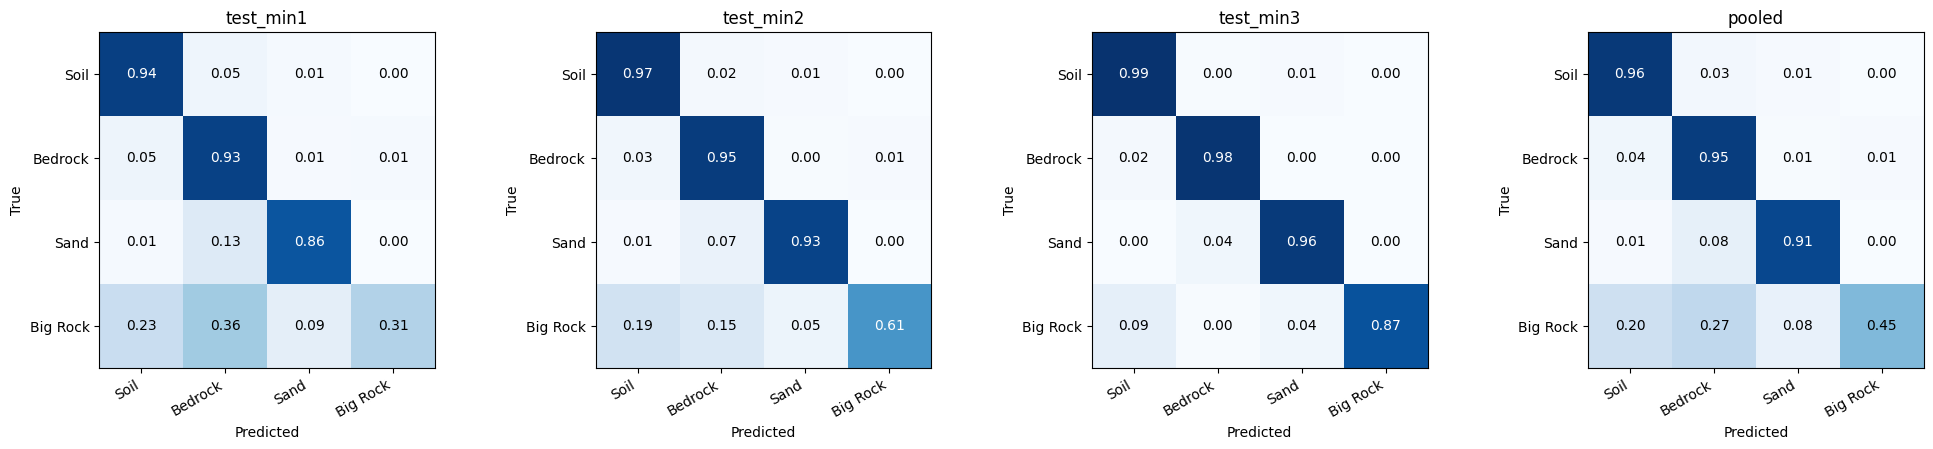

In [5]:
# E5: where does each class go? (rows = true class, each row sums to 1)
import matplotlib.pyplot as plt
from src.evaluation.metrics import scores_from_confusion
from src.utils.visualization import plot_confusion_matrix

pooled = sum(confusions.values())
pooled_scores = scores_from_confusion(pooled)
print(f"Pooled over all test pixels: mIoU {pooled_scores['miou']:.4f} | "
      f"IoU {[round(float(v), 3) for v in pooled_scores['iou']]}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (split, conf) in zip(axes, list(confusions.items()) + [("pooled", pooled)]):
    plot_confusion_matrix(conf, ax, title=split)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

Showing test_min1 samples: [8, 16, 20, 0, 1] | with Big Rock: [8, 16, 20]


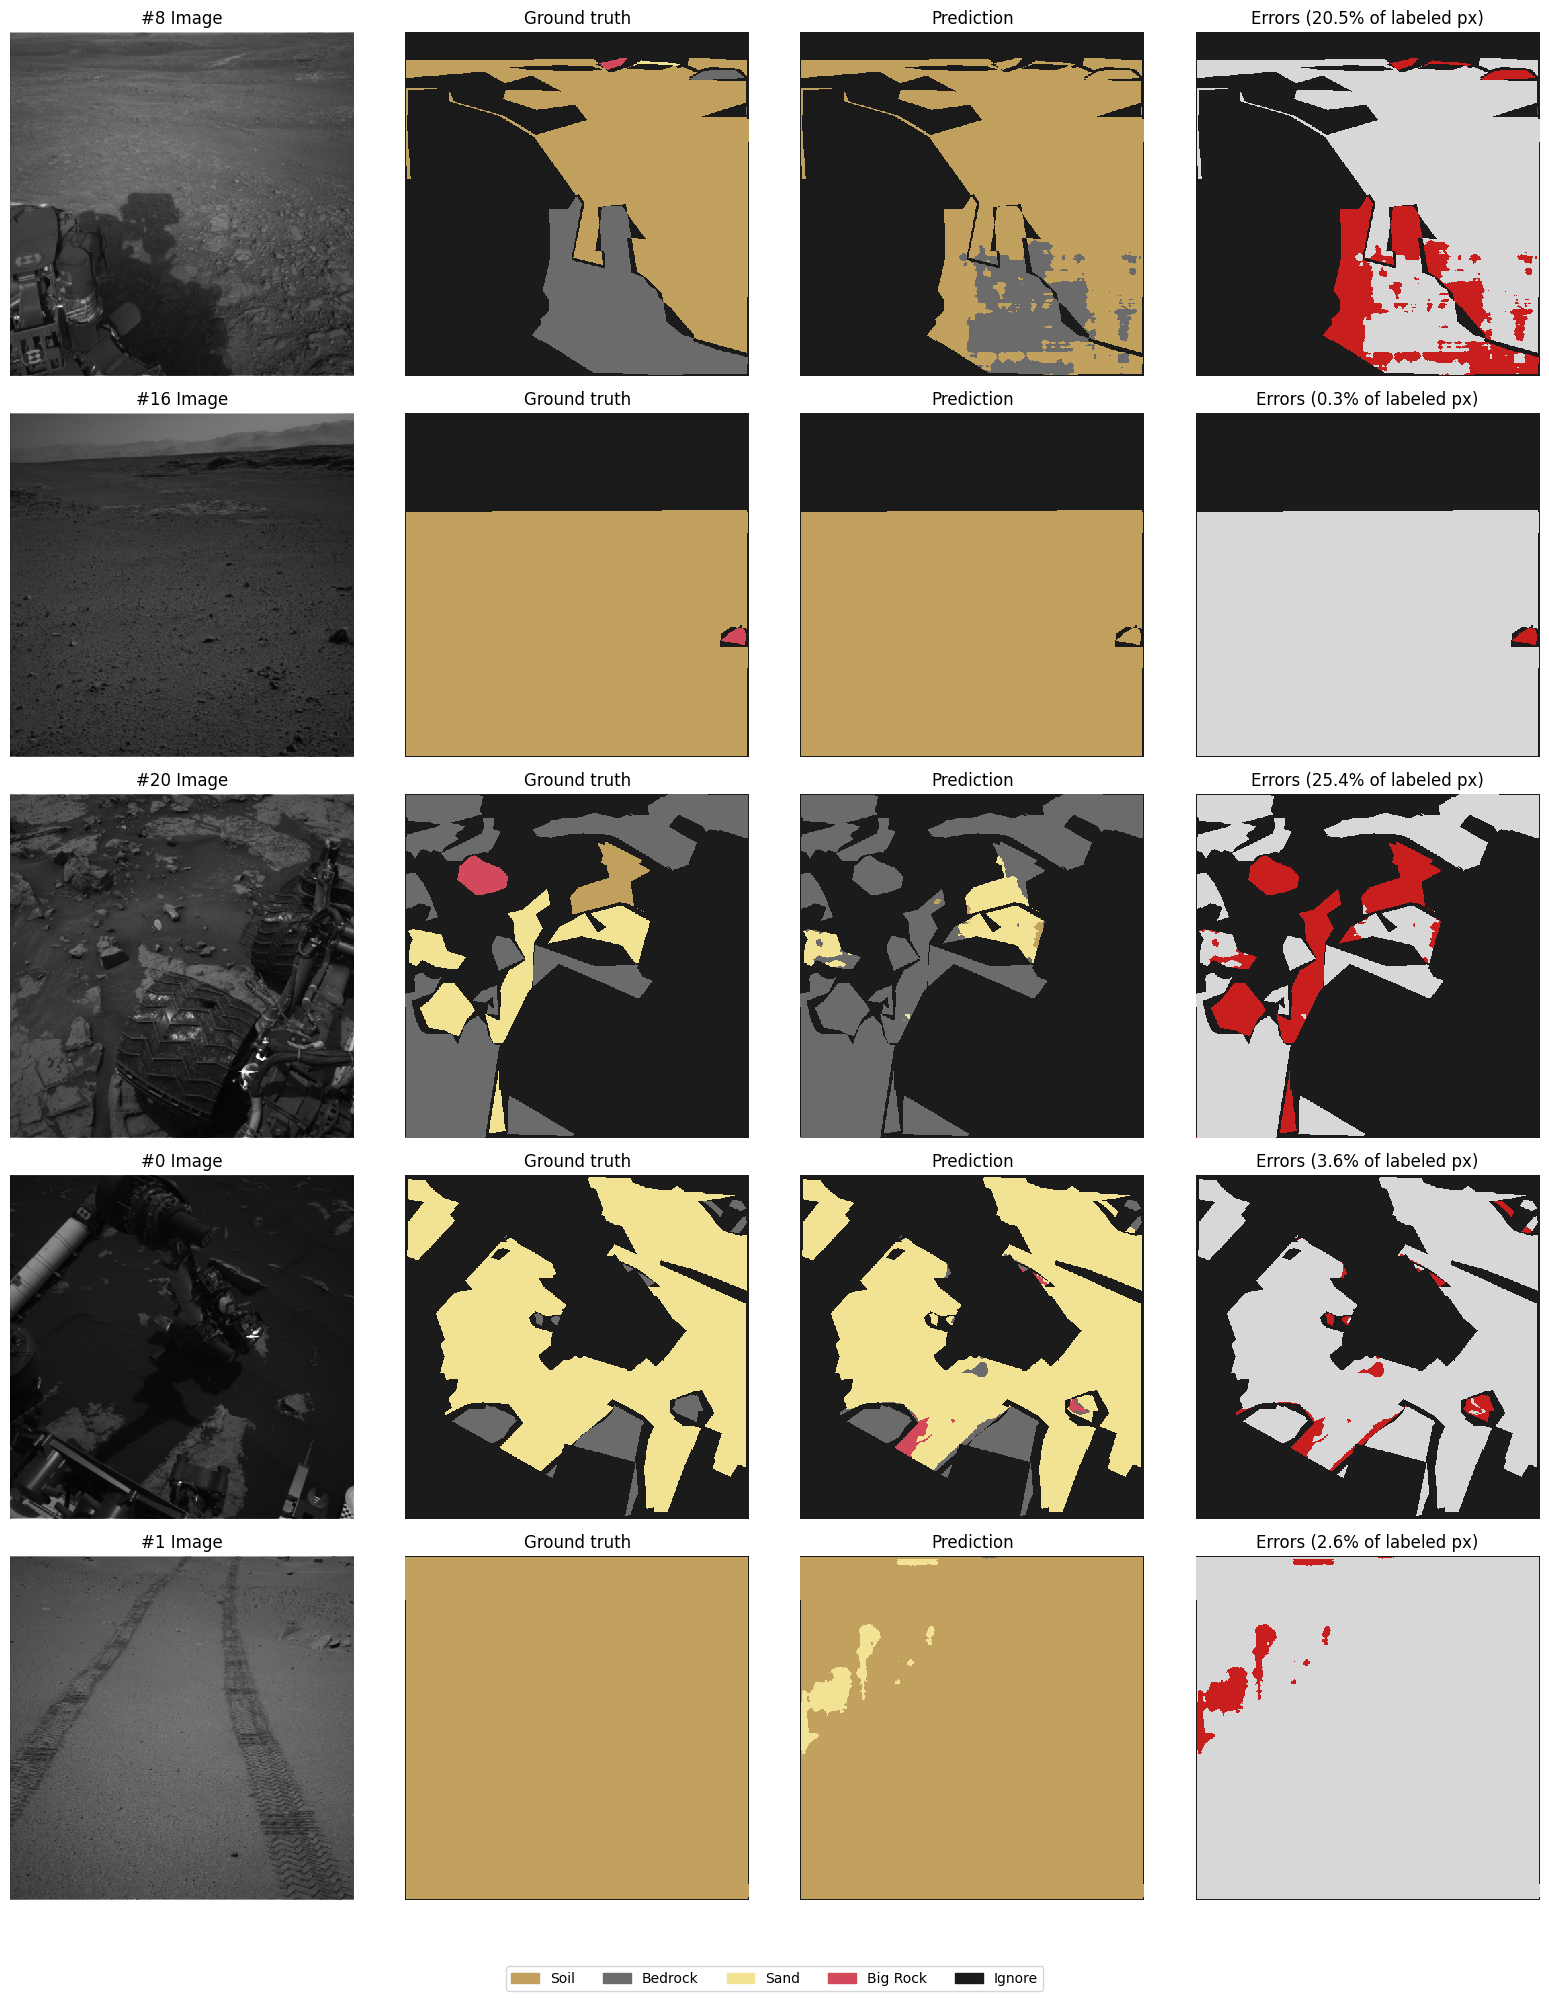

In [6]:
# E6: look at predictions, including Big Rock examples from the hardest split
from src.utils.visualization import find_indices_with_class, show_predictions

ds = test_loaders["test_min1"].dataset
big_rock_idx = find_indices_with_class(ds, class_id=3, n=3, max_scan=150)
indices = list(dict.fromkeys(big_rock_idx + [0, 1]))   # remove duplicates, keep order
print("Showing test_min1 samples:", indices, "| with Big Rock:", big_rock_idx)

show_predictions(model, ds, indices, device, use_amp=use_amp)

In [7]:
# E7: what this notebook produced
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(p.relative_to(OUT_DIR), f"({p.stat().st_size / 1e3:.0f} KB)")

confusion_matrices.png (98 KB)
test_results.csv (1 KB)
test_results.json (1 KB)
